In [1]:
%pip install -q ldpc
import numpy as np, ldpc
from ldpc import mod2
print(np.__version__, ldpc.__version__)

Note: you may need to restart the kernel to use updated packages.
1.26.4 2.4.1


In [2]:
import sys; sys.path.append("..")  # bb_code.py lives in the repo root
from bb_code import shift_matrix, bb_code, is_failure
print(shift_matrix(3))

[[0 1 0]
 [0 0 1]
 [1 0 0]]


In [3]:
H_X, H_Z = bb_code()
print(H_X.shape, H_Z.shape)

(36, 72) (36, 72)


In [4]:
# 1. X and Z stabilizers commute: H_X · H_Z^T must be all zeros mod 2
print("commute:", not ((H_X @ H_Z.T) % 2).any())

# 2. LDPC structure: every row weight 6, every column weight 3
print("row weights:", set(H_X.sum(axis=1)), "col weights:", set(H_X.sum(axis=0)))

# 3. number of logical qubits
k = 72 - mod2.rank(H_X) - mod2.rank(H_Z)
print("k =", k)

commute: True
row weights: {6} col weights: {3}
k = 12


In [5]:
from ldpc import BpDecoder
help(BpDecoder)

Help on class BpDecoder in module ldpc.bp_decoder._bp_decoder:

class BpDecoder(BpDecoderBase)
 |  BpDecoder(pcm: Union[np.ndarray, scipy.sparse.spmatrix], float error_rate: Optional[float] = None, error_channel: Optional[Union[np.ndarray, List[float]]] = None, int max_iter: Optional[int] = 0, str bp_method: Optional[str] = 'minimum_sum', ms_scaling_factor: Optional[Union[float, int]] = 1.0, str schedule: Optional[str] = 'parallel', int omp_thread_count: Optional[int] = 1, int random_schedule_seed: Optional[int] = 0, list serial_schedule_order: Optional[List[int]] = None, str input_vector_type: str = 'auto', bool random_serial_schedule: bool = False, **kwargs)
 |  
 |  Belief propagation decoder for binary linear codes.
 |  
 |  This class provides an implementation of belief propagation decoding for binary linear codes. The decoder uses a sparse
 |  parity check matrix to decode received codewords. The decoding algorithm can be configured using various parameters,
 |  such as the beli

In [6]:
# ---------- settings ----------
rng = np.random.default_rng(42)   # fixed seed → same "random" error every run
p = 0.03                          # physical error rate
n = H_Z.shape[1]                  # 72 qubits

# ---------- 1. true error (the decoder never sees this) ----------
e = (rng.random(n) < p).astype(np.uint8)

# ---------- 2. syndrome (the only thing the decoder sees) ----------
s = ((H_Z @ e) % 2).astype(np.uint8)

print(f"error weight: {e.sum()} | checks fired: {s.sum()}")

# ---------- 3. decode the SAME syndrome with all three schedules ----------
schedules = {
    "flooding":      dict(schedule="parallel"),
    "fixed serial":  dict(schedule="serial"),
    "random serial": dict(schedule="serial", random_serial_schedule=True, random_schedule_seed=1),
}

for name, opts in schedules.items():
    dec = BpDecoder(H_Z, error_rate=p, max_iter=50, bp_method="minimum_sum", **opts)
    e_hat = dec.decode(s)            # decoder's guess of the error
    r = (e + e_hat) % 2              # what's left after correction
    print(f"{name:14s} converged={dec.converge}  iterations={dec.iter}  residual weight={r.sum()}")

error weight: 1 | checks fired: 3
flooding       converged=True  iterations=1  residual weight=0
fixed serial   converged=True  iterations=1  residual weight=0
random serial  converged=True  iterations=1  residual weight=0


In [7]:
for length in (72, 36):
    try:
        dec = BpDecoder(H_Z, error_rate=p, max_iter=50, schedule="serial",
                        serial_schedule_order=list(range(length)))
        dec.decode(s)
        print(length, "→ works")
    except Exception as err:
        print(length, "→ fails:", err)

72 → works
36 → fails: Input error. The `serial_schedule_order` input parameter must have length equal to the length of the code.


In [8]:
rank_HX = mod2.rank(H_X)
ps = [0.02, 0.03, 0.04, 0.05, 0.06, 0.08]   # physical error rates to test
shots = 2000                                 # shots per (schedule, p)
results = {}                                 # (schedule, p) → (LER, avg iterations)

for name, opts in schedules.items():
    for p in ps:
        rng = np.random.default_rng(123)     # SAME seed → every schedule sees the SAME errors
        dec = BpDecoder(H_Z, error_rate=p, max_iter=50, bp_method="minimum_sum", **opts)
        fails, iters = 0, []
        for _ in range(shots):
            e = (rng.random(n) < p).astype(np.uint8)
            s = ((H_Z @ e) % 2).astype(np.uint8)
            e_hat = dec.decode(s)
            fails += is_failure(H_X, rank_HX, e, e_hat, dec.converge)
            iters.append(dec.iter)
        results[(name, p)] = (fails / shots, np.mean(iters))
        print(f"{name:14s} p={p:.2f}  LER={fails/shots:.4f}  avg iters={np.mean(iters):.2f}")

flooding       p=0.02  LER=0.0625  avg iters=5.76
flooding       p=0.03  LER=0.1795  avg iters=12.12
flooding       p=0.04  LER=0.3400  avg iters=19.51
flooding       p=0.05  LER=0.4945  avg iters=26.35
flooding       p=0.06  LER=0.6265  avg iters=32.53
flooding       p=0.08  LER=0.8095  avg iters=40.98
fixed serial   p=0.02  LER=0.0190  avg iters=3.78
fixed serial   p=0.03  LER=0.0680  avg iters=7.55
fixed serial   p=0.04  LER=0.2600  avg iters=15.30
fixed serial   p=0.05  LER=0.4305  avg iters=22.36
fixed serial   p=0.06  LER=0.5220  avg iters=27.28
fixed serial   p=0.08  LER=0.7760  avg iters=38.59
random serial  p=0.02  LER=0.0190  avg iters=4.02
random serial  p=0.03  LER=0.0670  avg iters=7.52
random serial  p=0.04  LER=0.2650  avg iters=15.63
random serial  p=0.05  LER=0.4240  avg iters=21.87
random serial  p=0.06  LER=0.5270  avg iters=27.61
random serial  p=0.08  LER=0.7620  avg iters=37.70


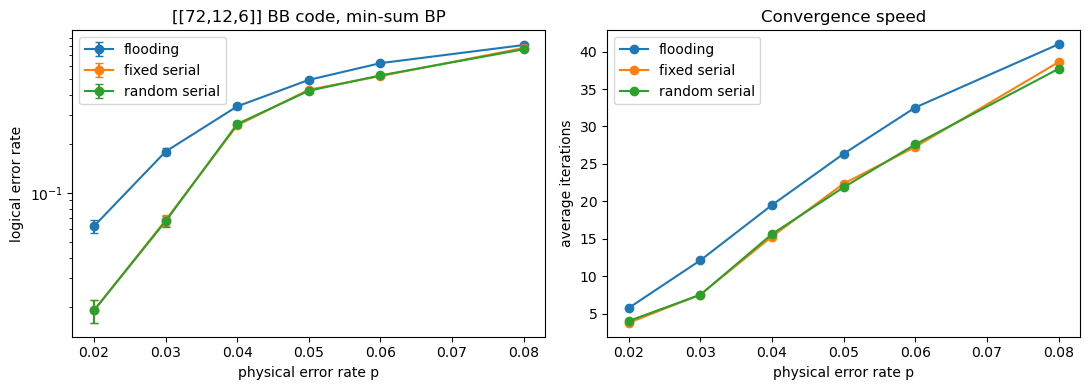

In [9]:
import matplotlib.pyplot as plt
import pickle

# save the raw numbers so you never have to rerun the sweep
with open("taskA_results.pkl", "wb") as f:
    pickle.dump({"results": results, "ps": ps, "shots": shots}, f)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

for name in schedules:
    ler   = np.array([results[(name, p)][0] for p in ps])
    iters = [results[(name, p)][1] for p in ps]
    err   = np.sqrt(ler * (1 - ler) / shots)        # binomial standard error

    ax1.errorbar(ps, ler, yerr=err, marker="o", capsize=3, label=name)
    ax2.plot(ps, iters, marker="o", label=name)

ax1.set_yscale("log")
ax1.set_xlabel("physical error rate p"); ax1.set_ylabel("logical error rate")
ax1.set_title("[[72,12,6]] BB code, min-sum BP")
ax2.set_xlabel("physical error rate p"); ax2.set_ylabel("average iterations")
ax2.set_title("Convergence speed")
ax1.legend(); ax2.legend()

fig.tight_layout()
fig.savefig("taskA_baselines.png", dpi=200, bbox_inches="tight")
plt.show()